# 4. Robustez frente al ruido: simulación Monte Carlo

**Proyecto Integrador · Métodos Numéricos · Entrega final**  
David Castro, Alejandro Pardo, Tomás Rincón · Docente: Edwin Fernando Muñoz  
Artículo base: Cartis & Roberts (2019), *A derivative-free Gauss–Newton method*.

Estima, con intervalos de confianza, la probabilidad de que cada método alcance la tolerancia cuando las evaluaciones tienen ruido, y mide el efecto de la protección del radio $\rho_k$. Genera las Figuras 2 y 3. Tarda unos minutos.

El cuaderno es autónomo: basta con ejecutar todas las celdas en Colab o Jupyter.

In [1]:
import time, csv
from dataclasses import dataclass
from pathlib import Path
from typing import Callable
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares  # solo para validar y para la f* de referencia

## Código de apoyo

Copia exacta de lo explicado en los cuadernos 1 y 2, para que este cuaderno funcione sin otros archivos.

In [2]:
def eliminacion_gauss(A, B):
    """Eliminación hacia adelante con pivoteo parcial.

    A es n x n; B es n x p (p lados derechos). Con una sola eliminación se
    resuelven los p sistemas, que es la misma ventaja que tiene LU (Quiz 3, 2g).
    El multiplicador es m = a_ji / a_ii y la actualización a_jk := a_jk - m a_ik.

    Devuelve U, B modificada y razon_pivotes = min|u_ii| / max|u_ii|. Si la razón
    es casi cero, A está cerca de ser singular.
    """
    U = np.array(A, dtype=float)
    C = np.array(B, dtype=float)
    n = U.shape[0]
    for i in range(n - 1):
        # Pivoteo parcial: se sube la fila con el mayor |a_ji| para que |m| <= 1
        # y los errores de redondeo no se amplifiquen.
        p = i + int(np.argmax(np.abs(U[i:, i])))
        if U[p, i] == 0.0:
            raise np.linalg.LinAlgError("Matriz singular en la eliminación de Gauss.")
        if p != i:
            U[[i, p]] = U[[p, i]]
            C[[i, p]] = C[[p, i]]
        for j in range(i + 1, n):
            m = U[j, i] / U[i, i]
            U[j, i] = 0.0
            U[j, i + 1:] -= m * U[i, i + 1:]
            C[j] -= m * C[i]
    pivotes = np.abs(np.diag(U))
    razon = pivotes.min() / pivotes.max() if pivotes.max() > 0 else 0.0
    return U, C, razon


def sustitucion_atras(U, c):
    """Resuelve Ux = c con U triangular superior. c puede tener varias columnas."""
    n = U.shape[0]
    x = np.array(c, dtype=float)
    for i in range(n - 1, -1, -1):
        if U[i, i] == 0.0:
            raise np.linalg.LinAlgError("Pivote nulo en la sustitución hacia atrás.")
        x[i] = (x[i] - U[i, i + 1:] @ x[i + 1:]) / U[i, i]
    return x


def resolver_gauss(A, B):
    """Resuelve AX = B. Devuelve X y la razón de pivotes."""
    U, C, razon = eliminacion_gauss(A, B)
    return sustitucion_atras(U, C), razon


def gram_schmidt_modificado(A, tol=1e-13):
    """QR reducida A = QR (m >= n), igual al notebook de la Semana 6.

    Cada columna v_j se actualiza justo después de cada proyección:
    v_j := v_j - r_ij q_i. tol es relativa a la mayor columna de A.
    """
    V = np.array(A, dtype=float)
    m, n = V.shape
    if m < n:
        raise ValueError("Se requiere m >= n.")
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    escala = max(np.linalg.norm(V, axis=0).max(), 1e-300)
    for i in range(n):
        R[i, i] = np.linalg.norm(V[:, i])
        if R[i, i] <= tol * escala:
            raise np.linalg.LinAlgError("Columnas linealmente dependientes.")
        Q[:, i] = V[:, i] / R[i, i]
        for j in range(i + 1, n):
            R[i, j] = Q[:, i] @ V[:, j]
            V[:, j] -= R[i, j] * Q[:, i]
    return Q, R


def minimos_cuadrados_qr(A, b):
    """Solución de min ||Ax - b||_2 mediante Rx = Q^T b (Sesión 12).

    Q^T b se calcula proyectando b de forma secuencial, con la misma idea de
    Gram-Schmidt modificado; así se conserva mejor la precisión si Q pierde
    algo de ortogonalidad.
    """
    Q, R = gram_schmidt_modificado(A)
    v = np.array(b, dtype=float)
    c = np.zeros(R.shape[0])
    for i in range(R.shape[0]):
        c[i] = Q[:, i] @ v
        v -= c[i] * Q[:, i]
    return sustitucion_atras(R, c)

In [3]:
@dataclass
class Problema:
    numero: int            # número en la Tabla 2
    nombre: str
    r: Callable            # residuos, R^n -> R^m
    J: Callable            # Jacobiano analítico, m x n
    x0: np.ndarray
    dos_f0_tabla: float
    dos_f_estrella: float

    @property
    def f_estrella(self):
        return self.dos_f_estrella / 2

    @property
    def n(self):
        return len(self.x0)

    @property
    def m(self):
        return len(self.r(self.x0))


def _rosenbrock_r(x):
    return np.array([10 * (x[1] - x[0] ** 2), 1 - x[0]])


def _rosenbrock_J(x):
    return np.array([[-20 * x[0], 10.0], [-1.0, 0.0]])


def _freudenstein_r(x):
    return np.array([-13 + x[0] + ((5 - x[1]) * x[1] - 2) * x[1],
                     -29 + x[0] + ((x[1] + 1) * x[1] - 14) * x[1]])


def _freudenstein_J(x):
    return np.array([[1.0, 10 * x[1] - 3 * x[1] ** 2 - 2],
                     [1.0, 3 * x[1] ** 2 + 2 * x[1] - 14]])


def _theta(x):
    t = np.arctan(x[1] / x[0]) / (2 * np.pi) if x[0] != 0 else 0.25
    return t + 0.5 if x[0] < 0 else t


def _helical_r(x):
    return np.array([10 * (x[2] - 10 * _theta(x)),
                     10 * (np.hypot(x[0], x[1]) - 1), x[2]])


def _helical_J(x):
    d2 = x[0] ** 2 + x[1] ** 2
    d = np.sqrt(d2)
    return np.array([[100 * x[1] / (2 * np.pi * d2), -100 * x[0] / (2 * np.pi * d2), 10.0],
                     [10 * x[0] / d, 10 * x[1] / d, 0.0],
                     [0.0, 0.0, 1.0]])


_BARD_Y = np.array([0.14, 0.18, 0.22, 0.25, 0.29, 0.32, 0.35, 0.39, 0.37, 0.58,
                    0.73, 0.96, 1.34, 2.10, 4.39])
_BARD_U = np.arange(1.0, 16.0)
_BARD_V = 16.0 - _BARD_U
_BARD_W = np.minimum(_BARD_U, _BARD_V)


def _bard_r(x):
    return _BARD_Y - (x[0] + _BARD_U / (_BARD_V * x[1] + _BARD_W * x[2]))


def _bard_J(x):
    d = (_BARD_V * x[1] + _BARD_W * x[2]) ** 2
    return np.column_stack((-np.ones(15), _BARD_U * _BARD_V / d, _BARD_U * _BARD_W / d))


def _powell_r(x):
    return np.array([x[0] + 10 * x[1], np.sqrt(5) * (x[2] - x[3]),
                     (x[1] - 2 * x[2]) ** 2, np.sqrt(10) * (x[0] - x[3]) ** 2])


def _powell_J(x):
    a = 2 * (x[1] - 2 * x[2])
    b = 2 * np.sqrt(10) * (x[0] - x[3])
    s = np.sqrt(5)
    return np.array([[1.0, 10.0, 0.0, 0.0], [0.0, 0.0, s, -s],
                     [0.0, a, -2 * a, 0.0], [b, 0.0, 0.0, -b]])


_KO_Y = np.array([0.1957, 0.1947, 0.1735, 0.1600, 0.0844, 0.0627, 0.0456,
                  0.0342, 0.0323, 0.0235, 0.0246])
_KO_U = np.array([4.0, 2.0, 1.0, 0.5, 0.25, 0.1670, 0.1250, 0.1000, 0.0833,
                  0.0714, 0.0625])


def _kowalik_r(x):
    u = _KO_U
    return _KO_Y - x[0] * (u ** 2 + u * x[1]) / (u ** 2 + u * x[2] + x[3])


def _kowalik_J(x):
    u = _KO_U
    num = u ** 2 + u * x[1]
    den = u ** 2 + u * x[2] + x[3]
    return np.column_stack((-num / den, -x[0] * u / den,
                            x[0] * num * u / den ** 2, x[0] * num / den ** 2))


def _watson_r(x):
    n = len(x)
    t = np.arange(1, 30) / 29.0
    pot = np.vander(t, n, increasing=True)            # t^(j-1), j = 1..n
    suma = pot @ x
    deriv = pot[:, :-1] @ (np.arange(1, n) * x[1:])   # suma de (j-1) x_j t^(j-2)
    return np.concatenate((deriv - suma ** 2 - 1, [x[0], x[1] - x[0] ** 2 - 1]))


def _watson_J(x):
    n = len(x)
    t = np.arange(1, 30) / 29.0
    pot = np.vander(t, n, increasing=True)
    suma = pot @ x
    J = np.zeros((31, n))
    J[:29, 0] = -2 * suma
    J[:29, 1:] = pot[:, :-1] * np.arange(1, n) - 2 * suma[:, None] * pot[:, 1:]
    J[29, 0] = 1.0
    J[30, 0] = -2 * x[0]
    J[30, 1] = 1.0
    return J


PROBLEMAS = [
    Problema(7, "Rosenbrock", _rosenbrock_r, _rosenbrock_J, np.array([-1.2, 1.0]), 24.2, 0.0),
    Problema(13, "Freudenstein & Roth", _freudenstein_r, _freudenstein_J,
             np.array([0.5, -2.0]), 400.5, 48.98425),
    Problema(9, "Helical Valley", _helical_r, _helical_J, np.array([-1.0, 0.0, 0.0]), 2500.0, 0.0),
    Problema(15, "Bard", _bard_r, _bard_J, np.array([1.0, 1.0, 1.0]), 41.68170, 8.214877e-3),
    Problema(11, "Powell Singular", _powell_r, _powell_J,
             np.array([3.0, -1.0, 0.0, 1.0]), 215.0, 0.0),
    Problema(17, "Kowalik & Osborne", _kowalik_r, _kowalik_J,
             np.array([0.25, 0.39, 0.415, 0.39]), 5.313172e-3, 3.075056e-4),
    Problema(19, "Watson", _watson_r, _watson_J, 0.5 * np.ones(6), 16.43083, 2.287670e-3),
]


class Evaluador:
    """Envuelve r(x): cuenta evaluaciones y, si se pide, agrega ruido (sección 5.2 del artículo).

    ruido = None, 'multiplicativo' (r_i (1 + e)) o 'aditivo' (r_i + e), con
    e ~ N(0, sigma^2) independiente por componente y por evaluación.
    'uniforme' es multiplicativo con e ~ U(a, b), generado por transformada
    inversa (Semana 14): e = a + (b - a) U, con U ~ U(0, 1). Con a = -sqrt(3) sigma
    y b = sqrt(3) sigma tiene media 0 y la misma varianza sigma^2 que el gaussiano.
    """

    def __init__(self, problema, ruido=None, sigma=1e-2, semilla=None):
        self.problema = problema
        self.ruido = ruido
        self.sigma = sigma
        self.rng = np.random.default_rng(semilla)
        self.n_eval = 0
        self.n_eval_J = 0

    def r(self, x):
        self.n_eval += 1
        valor = self.problema.r(x)
        if self.ruido is None:
            return valor
        if self.ruido == "uniforme":
            a, b = -np.sqrt(3) * self.sigma, np.sqrt(3) * self.sigma
            e = a + (b - a) * self.rng.random(valor.shape)
            return valor * (1 + e)
        e = self.rng.normal(0.0, self.sigma, valor.shape)
        return valor * (1 + e) if self.ruido == "multiplicativo" else valor + e

    def J(self, x):
        self.n_eval_J += 1
        return self.problema.J(x)

    def f_real(self, x):
        """f sin ruido y sin contar: solo para medir, nunca la usa el algoritmo."""
        return 0.5 * float(np.sum(self.problema.r(x) ** 2))

In [4]:
ETA1, ETA2 = 0.1, 0.7          # umbrales de aceptación
GAMMA_DEC, GAMMA_INC = 0.5, 2.0
DELTA_MAX = 1e10
DELTA_FIN = 1e-10
RAZON_MIN = 1e-8               # geometría: razón de pivotes mínima de W/Delta
ALFA1, ALFA2 = 0.1, 0.5        # reducción de rho: (rho, Delta) <- (alfa1 rho, alfa2 rho)
RHO_FIN = 1e-10                # rho_end del artículo (sección 5.1)
RECHAZOS_PARA_BAJAR_RHO = 3    # sección 4.5: rho baja tras 3 rechazos seguidos


def radio_inicial(x0):
    """Delta_0 = 0.1 max(||x0||_inf, 1), como en la sección 5.1 del artículo."""
    return 0.1 * max(np.linalg.norm(x0, np.inf), 1.0)


def paso_cauchy(g, H, delta):
    """Minimiza el modelo sobre -g dentro de la región: s = -t g.

    Es descenso del gradiente con la tasa óptima para el modelo cuadrático:
    t = g'g / g'Hg, recortada a delta / ||g||.
    """
    norma_g = np.linalg.norm(g)
    curvatura = g @ H @ g
    t_borde = delta / norma_g
    t = min(norma_g ** 2 / curvatura, t_borde) if curvatura > 0 else t_borde
    return -t * g


def valor_modelo(g, H, s):
    """Cambio del modelo m(s) - m(0) = g's + 1/2 s'Hs (ec. 2.5)."""
    return g @ s + 0.5 * s @ H @ s


def paso_gn_qr(J, r, g, H, delta):
    """Paso de Gauss-Newton: min ||J s + r|| por QR, recortado al radio delta.

    Si J está casi singular, el paso recortado puede bajar el modelo menos que el
    de Cauchy e incumplir la condición 2.8 del artículo, que sostiene la
    convergencia global. Por eso se devuelve el mejor de los dos según el modelo.
    """
    cauchy = paso_cauchy(g, H, delta)
    try:
        s = minimos_cuadrados_qr(J, -r)
    except np.linalg.LinAlgError:
        return cauchy
    norma = np.linalg.norm(s)
    if norma > delta:
        s = s * (delta / norma)
    return s if valor_modelo(g, H, s) <= valor_modelo(g, H, cauchy) else cauchy


class JacobianoExacto:
    def __init__(self, ev, x, rx, delta):
        self.ev = ev
        self.J = ev.J(x)

    def tras_paso(self, x_nuevo, r_nuevo, aceptado, x, rx, delta):
        if aceptado:
            self.J = self.ev.J(x_nuevo)


class JacobianoDiferencias:
    """Diferencias finitas hacia adelante (Unidad 2): n evaluaciones por Jacobiano."""
    H_BASE = np.sqrt(np.finfo(float).eps)   # paso óptimo aprox. sqrt(épsilon), Unidad 1

    def __init__(self, ev, x, rx, delta):
        self.ev = ev
        self.J = self._calcular(x, rx)

    def _calcular(self, x, rx):
        J = np.zeros((len(rx), len(x)))
        for j in range(len(x)):
            h = self.H_BASE * max(1.0, abs(x[j]))
            y = x.copy()
            y[j] += h
            J[:, j] = (self.ev.r(y) - rx) / h
        return J

    def tras_paso(self, x_nuevo, r_nuevo, aceptado, x, rx, delta):
        if aceptado:
            self.J = self._calcular(x_nuevo, r_nuevo)


class JacobianoInterpolacion:
    """Jacobiano de DFO-GN: interpolación lineal con n+1 puntos (ec. 2.2 a 2.4).

    Por cada residuo r_i se pide m_i(y_t - x) = r_i(y_t). Con W de filas (y_t - x)'
    y D de filas r(y_t) - r(x), eso equivale a W J' = D, que se resuelve con una
    sola eliminación de Gauss para los m residuos.
    """

    def __init__(self, ev, x, rx, delta):
        self.ev = ev
        self._reconstruir(x, delta)
        self._ajustar(x, rx, delta)

    def _reconstruir(self, x, delta):
        """Y = {x + delta e_j}: base canónica, la geometría ideal. Cuesta n evaluaciones."""
        self.Y = [x + delta * e for e in np.eye(len(x))]
        self.rY = [self.ev.r(y) for y in self.Y]

    def _sistema(self, x, rx, delta):
        W = np.array([y - x for y in self.Y]) / delta   # se escala para medir solo la forma
        D = np.array([ry - rx for ry in self.rY]) / delta
        return resolver_gauss(W, D)

    def _ajustar(self, x, rx, delta):
        try:
            Jt, razon = self._sistema(x, rx, delta)
        except np.linalg.LinAlgError:
            razon = 0.0
        if razon < RAZON_MIN:              # puntos casi alineados: geometría degenerada
            self._reconstruir(x, delta)
            Jt, razon = self._sistema(x, rx, delta)
        self.J = Jt.T

    def tras_paso(self, x_nuevo, r_nuevo, aceptado, x, rx, delta):
        """Entra el punto de prueba y sale el más lejano del centro de la región."""
        centro, r_centro = (x_nuevo, r_nuevo) if aceptado else (x, rx)
        puntos = self.Y + [x if aceptado else x_nuevo]
        valores = self.rY + [rx if aceptado else r_nuevo]
        distancias = [np.linalg.norm(p - centro) for p in puntos]
        sale = int(np.argmax(distancias))
        del puntos[sale], valores[sale]
        self.Y, self.rY = puntos, valores
        # Tras un rechazo, si los puntos quedaron lejos el modelo ya no representa
        # la región; se reconstruye en vez de seguir encogiendo el radio.
        if not aceptado and max(np.linalg.norm(p - centro) for p in self.Y) > 2 * delta:
            self._reconstruir(centro, delta)
        self._ajustar(centro, r_centro, delta)


def region_confianza(ev, tipo_J, tipo_paso, presupuesto=None, proteger_radio=False):
    """Región de confianza con cociente R_k (ec. 2.6, 2.7 y regla 2.15).

    Con proteger_radio=True se añade el radio inferior rho_k del Algoritmo 1:
    Delta nunca baja de rho, y rho solo se reduce, por un factor alfa1, cuando
    Delta ya está en rho y hubo varios rechazos seguidos. Así un rechazo causado
    por el ruido no encoge la región sin límite.
    """
    inicio = time.perf_counter()
    x = ev.problema.x0.astype(float).copy()
    n = len(x)
    presupuesto = presupuesto or 200 * (n + 1)
    delta = radio_inicial(x)
    rho = delta                       # rho_0 = Delta_0 (sección 5.1 del artículo)
    rechazos = 0
    rx = ev.r(x)
    fx = 0.5 * rx @ rx
    f0 = fx
    clases = {"interpolacion": JacobianoInterpolacion, "exacto": JacobianoExacto,
              "diferencias": JacobianoDiferencias}
    modelo = clases[tipo_J](ev, x, rx, delta)
    calcular_paso = paso_cauchy if tipo_paso == "cauchy" else None
    historial = [(ev.n_eval, ev.f_real(x), 0)]
    radios = [(ev.n_eval, delta)]     # para graficar cómo evoluciona la región
    iterados = [x.copy()]
    motivo = "presupuesto"
    k = 0
    while ev.n_eval < presupuesto:
        k += 1
        J = modelo.J
        g = J.T @ rx
        H = J.T @ J
        if fx <= max(1e-12, 1e-20 * f0):
            motivo = "f pequeña"
            break
        if (rho if proteger_radio else delta) < DELTA_FIN:
            motivo = "radio pequeño"
            break
        if np.linalg.norm(g) == 0.0:
            motivo = "gradiente nulo"
            break
        s = calcular_paso(g, H, delta) if calcular_paso else paso_gn_qr(J, rx, g, H, delta)
        x_nuevo = x + s
        r_nuevo = ev.r(x_nuevo)
        f_nuevo = 0.5 * r_nuevo @ r_nuevo
        predicha = -valor_modelo(g, H, s)
        R = (fx - f_nuevo) / predicha if predicha > 0 else -1.0
        if not np.isfinite(R):
            R = -1.0
        aceptado = R >= ETA1
        norma_s = np.linalg.norm(s)
        if R >= ETA2:
            delta = min(max(GAMMA_INC * delta, GAMMA_INC * norma_s), DELTA_MAX)
        elif aceptado:
            delta = max(GAMMA_DEC * delta, norma_s)
        else:
            delta = min(GAMMA_DEC * delta, norma_s)
        if proteger_radio:
            rechazos = 0 if aceptado else rechazos + 1
            delta = max(delta, rho)
            if not aceptado and delta == rho and rechazos >= RECHAZOS_PARA_BAJAR_RHO:
                rho, delta = ALFA1 * rho, ALFA2 * rho
                rechazos = 0
        modelo.tras_paso(x_nuevo, r_nuevo, aceptado, x, rx, delta)
        if aceptado:
            x, rx, fx = x_nuevo, r_nuevo, f_nuevo
            iterados.append(x.copy())
        historial.append((ev.n_eval, ev.f_real(x), k))
        radios.append((ev.n_eval, delta))
    return {"x": x, "f": ev.f_real(x), "historial": historial, "n_eval": ev.n_eval,
            "n_eval_J": ev.n_eval_J, "n_iter": k, "motivo": motivo, "iterados": iterados, "radios": radios,
            "radio_final": delta, "rho_final": rho if proteger_radio else None, "tiempo": time.perf_counter() - inicio}


def descenso_gradiente(ev, eta, presupuesto=None):
    """x := x - eta grad f, con grad f = J'r y tasa fija (Sesión 23)."""
    inicio = time.perf_counter()
    x = ev.problema.x0.astype(float).copy()
    presupuesto = presupuesto or 200 * (len(x) + 1)
    historial = [(0, ev.f_real(x), 0)]
    motivo = "presupuesto"
    k = 0
    while ev.n_eval < presupuesto:
        k += 1
        g = ev.J(x).T @ ev.r(x)
        if not np.isfinite(g).all():
            motivo = "divergió"
            break
        x = x - eta * g
        with np.errstate(all="ignore"):
            f = ev.f_real(x)
        if not np.isfinite(f):
            motivo = "divergió"
            historial.append((ev.n_eval, np.inf, k))
            break
        historial.append((ev.n_eval, f, k))
    return {"x": x, "f": historial[-1][1], "historial": historial, "n_eval": ev.n_eval,
            "n_eval_J": ev.n_eval_J, "n_iter": k, "motivo": motivo,
            "tiempo": time.perf_counter() - inicio}

In [5]:
SEMILLA = 2026
SIGMA = 1e-2
TAUS = [1e-1, 1e-3, 1e-5]
ETAS = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
BASE = Path.cwd().parent if Path.cwd().name == "cuadernos" else Path.cwd()
RES = BASE / "resultados"
FIG = BASE / "figuras"
RES.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

# nombre: (origen de J, tipo de paso, proteger el radio con rho). El descenso del gradiente va aparte.
METODOS = {
    "DFO-GN QR + ρ": ("interpolacion", "qr", True),
    "DFO-GN QR": ("interpolacion", "qr", False),
    "GN dif. finitas QR": ("diferencias", "qr", False),
    "GN exacto QR": ("exacto", "qr", False),
    "DFO-GN Cauchy": ("interpolacion", "cauchy", False),
    "GN exacto Cauchy": ("exacto", "cauchy", False),
}
DG = "Descenso gradiente"
# Un color fijo por método, en el mismo orden en todas las figuras (paleta categórica validada).
COLORES = {"DFO-GN QR + ρ": "#2a78d6", "DFO-GN QR": "#eb6834", "GN dif. finitas QR": "#1baf7a",
           "GN exacto QR": "#eda100", "DFO-GN Cauchy": "#e87ba4", "GN exacto Cauchy": "#008300",
           DG: "#6250d6"}
MARCAS = {"DFO-GN QR + ρ": "o", "DFO-GN QR": "s", "GN dif. finitas QR": "D", "GN exacto QR": "^",
          "DFO-GN Cauchy": "v", "GN exacto Cauchy": "P", DG: "X"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "font.size": 9})

In [6]:
def correr(nombre, p, eta=None, ruido=None, semilla=None):
    """Ejecuta un método sobre un problema; con ruido, la semilla fija la secuencia."""
    ev = Evaluador(p, ruido=ruido, sigma=SIGMA, semilla=semilla)
    if nombre == DG:
        return descenso_gradiente(ev, eta)
    tipo_J, paso, rho = METODOS[nombre]
    return region_confianza(ev, tipo_J, paso, proteger_radio=rho)


def n_p(res, p, tau):
    """Ec. 5.1: primera evaluación con f(x_k) <= f* + tau (f(x0) - f*)."""
    f0 = res["historial"][0][1]
    meta = p.f_estrella + tau * (f0 - p.f_estrella)
    for n_eval, f, _ in res["historial"]:
        if f <= meta:
            return n_eval
    return None


def guardar(nombre, cabecera, filas):
    with open(RES / nombre, "w", newline="", encoding="utf-8") as a:
        w = csv.writer(a)
        w.writerow(cabecera)
        w.writerows(filas)

## 1. Diseño Monte Carlo (Semana 14-15)

1. **Cantidad a estimar:** la probabilidad $p$ de que un método alcance $\tau$ con ruido.
2. **Muestreo:** 100 semillas por problema, método y tipo de ruido; 8 400 corridas en total.
3. **Estimador:** la proporción de éxitos $\hat p$ = éxitos / corridas.
4. **Incertidumbre:** error estándar $\sqrt{\hat p(1-\hat p)/n}$ e intervalo del 95 % $\hat p\pm1.96\cdot EE$.

La corrida $k$ usa la semilla $2026+k$ en todos los métodos, así que todos reciben el mismo ruido. Eso permite comparar con ρ y sin ρ **por pares**: $d_k=I_{\text{con }\rho}-I_{\text{sin }\rho}$, con intervalo $\bar d\pm1.96\,s_d/\sqrt n$.

In [7]:
N_MC = 100          # corridas Monte Carlo por problema, método y tipo de ruido
RUIDOS = ["multiplicativo", "aditivo", "uniforme"]
METODOS_MC = ["DFO-GN QR + ρ", "DFO-GN QR", "GN dif. finitas QR", "GN exacto QR"]
Z = 1.96            # cuantil normal del 95 %


def corridas_monte_carlo():
    """Una fila por corrida. La corrida k usa la semilla SEMILLA + k en todos los métodos,
    así las diferencias entre métodos no se deben a haber recibido ruidos distintos."""
    refs = {p.nombre: (least_squares(p.r, p.x0, jac=p.J, xtol=1e-15, ftol=1e-15, gtol=1e-15).cost
                       if p.f_estrella > 0 else 0.0) for p in PROBLEMAS}
    filas = []
    for ruido in RUIDOS:
        for p in PROBLEMAS:
            for nombre in METODOS_MC:
                for k in range(N_MC):
                    r = correr(nombre, p, ruido=ruido, semilla=SEMILLA + k)
                    filas.append([ruido, p.nombre, nombre, k] + [int(n_p(r, p, t) is not None) for t in TAUS]
                                 + [r["f"] - refs[p.nombre], r["n_eval"], r["motivo"]])
    cab = ["ruido", "problema", "metodo", "corrida", "exito_1e-1", "exito_1e-3", "exito_1e-5",
           "brecha_f", "n_eval", "motivo"]
    guardar("e3_monte_carlo.csv", cab, filas)
    return pd.DataFrame(filas, columns=cab)


def intervalo(x):
    """Media muestral y su intervalo del 95 %: media ± 1.96 s/√n (Semana 14-15).
    Para un éxito 0/1 la media es la proporción p̂ y s/√n ≈ √(p̂(1−p̂)/n)."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    media = x.mean()
    ee = x.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    return media, ee, media - Z * ee, media + Z * ee


def resumen_exito(df, tau="exito_1e-3"):
    filas = []
    for (ruido, metodo), g in df.groupby(["ruido", "metodo"], sort=False):
        m, ee, a, b = intervalo(g[tau])
        filas.append([ruido, metodo, len(g), m, ee, max(a, 0.0), min(b, 1.0)])
    return pd.DataFrame(filas, columns=["ruido", "metodo", "n", "p_exito", "error_estandar", "ic95_inf", "ic95_sup"])


def diferencia_pareada(df, a="DFO-GN QR + ρ", b="DFO-GN QR", tau="exito_1e-3"):
    """Diferencia de éxito con la misma semilla: d = I_a − I_b por corrida, con su intervalo."""
    filas = []
    for ruido, g in df.groupby("ruido", sort=False):
        ga = g[g.metodo == a].set_index(["problema", "corrida"])[tau]
        gb = g[g.metodo == b].set_index(["problema", "corrida"])[tau]
        m, ee, lo, hi = intervalo((ga - gb.loc[ga.index]).values)
        filas.append([ruido, len(ga), m, ee, lo, hi])
    return pd.DataFrame(filas, columns=["ruido", "n_pares", "diferencia", "error_estandar", "ic95_inf", "ic95_sup"])


def figura_exito(res):
    fig, ejes = plt.subplots(1, 3, figsize=(12, 2.9), sharey=True)
    for eje, ruido in zip(ejes, RUIDOS):
        g = res[res.ruido == ruido].set_index("metodo").loc[METODOS_MC]
        y = np.arange(len(g))[::-1]
        for yi, (nombre, f) in zip(y, g.iterrows()):
            eje.plot([f.ic95_inf, f.ic95_sup], [yi, yi], color=COLORES[nombre], lw=2.2, solid_capstyle="round")
            eje.plot(f.p_exito, yi, MARCAS[nombre], color=COLORES[nombre], ms=8, mec="white", mew=1.5)
            eje.annotate(f"{100 * f.p_exito:.0f} %", (f.ic95_sup, yi), xytext=(6, 0), textcoords="offset points",
                         va="center", fontsize=8.5, color="#52514e")
        eje.set_yticks(y, METODOS_MC)
        eje.set_xlim(0, 1.12)
        eje.set_xticks([0, .25, .5, .75, 1], ["0", "25", "50", "75", "100 %"])
        eje.set_title(f"Ruido {ruido}, σ = {SIGMA}", fontsize=9.5)
        eje.grid(axis="y", visible=False)
    fig.supxlabel("Proporción de corridas que alcanzan τ = 10⁻³ (punto) e intervalo del 95 % (línea)", fontsize=9)
    fig.tight_layout()
    fig.savefig(FIG / "fig2_exito_ruido.png", dpi=170)
    plt.show()


def figura_estabilizacion(df, ruido="multiplicativo", tau="exito_1e-3"):
    """Estimación acumulada de p̂ al crecer el número de corridas: la banda ±1.96·EE se estrecha como 1/√n."""
    fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6))
    for nombre in ["DFO-GN QR + ρ", "DFO-GN QR"]:
        g = df[(df.ruido == ruido) & (df.metodo == nombre)].sort_values(["corrida", "problema"])
        x = g[tau].to_numpy(float)
        n = np.arange(1, len(x) + 1)
        p = np.cumsum(x) / n
        ee = np.sqrt(p * (1 - p) / n)
        ejes[0].plot(n, p, color=COLORES[nombre], lw=1.8, label=nombre)
        ejes[0].fill_between(n, np.clip(p - Z * ee, 0, 1), np.clip(p + Z * ee, 0, 1), color=COLORES[nombre], alpha=.15, lw=0)
        ejes[1].loglog(n[9:], ee[9:], color=COLORES[nombre], lw=1.8, label=nombre)
    ref = np.arange(10, 701)
    ejes[1].loglog(ref, 0.5 / np.sqrt(ref), color="#898781", lw=1.2, ls="--", label="0.5/√n (referencia)")
    ejes[0].set(xlabel="Corridas acumuladas (7 problemas por semilla)", ylabel="p̂ acumulada", ylim=(0, 1),
                title=f"Estimación de la proporción de éxito, ruido {ruido}")
    ejes[1].set(xlabel="Corridas acumuladas n", ylabel="Error estándar √(p̂(1−p̂)/n)", title="El error estándar cae como 1/√n")
    for e in ejes:
        e.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG / "fig3_estabilizacion_mc.png", dpi=170)
    plt.show()

## 2. Ejecución

In [8]:
df = corridas_monte_carlo()
df.head()

,ruido,problema,metodo,corrida,exito_1e-1,exito_1e-3,exito_1e-5,brecha_f,n_eval,motivo
0,multiplicativo,Rosenbrock,DFO-GN QR + ρ,0,0,0,0,2.040041,86,radio pequeño
1,multiplicativo,Rosenbrock,DFO-GN QR + ρ,1,1,0,0,0.495477,100,radio pequeño
2,multiplicativo,Rosenbrock,DFO-GN QR + ρ,2,0,0,0,1.823382,82,radio pequeño
3,multiplicativo,Rosenbrock,DFO-GN QR + ρ,3,0,0,0,2.068691,81,radio pequeño
4,multiplicativo,Rosenbrock,DFO-GN QR + ρ,4,0,0,0,2.069313,79,radio pequeño


## 3. Proporción de éxito con intervalo del 95 %, $\tau=10^{-3}$

In [9]:
res = resumen_exito(df)
guardar("e3_resumen_exito.csv", list(res.columns), res.values.tolist())
res.round(3)

,ruido,metodo,n,p_exito,error_estandar,ic95_inf,ic95_sup
0,multiplicativo,DFO-GN QR + ρ,700,0.684,0.018,0.650,0.719
1,multiplicativo,DFO-GN QR,700,0.551,0.019,0.515,0.588
2,multiplicativo,GN dif. finitas QR,700,0.000,0.000,0.000,0.000
3,multiplicativo,GN exacto QR,700,0.946,0.009,0.929,0.963
4,aditivo,DFO-GN QR + ρ,700,0.596,0.019,0.559,0.632
5,aditivo,DFO-GN QR,700,0.474,0.019,0.437,0.511
6,aditivo,GN dif. finitas QR,700,0.000,0.000,0.000,0.000
7,aditivo,GN exacto QR,700,0.857,0.013,0.831,0.883
8,uniforme,DFO-GN QR + ρ,700,0.691,0.017,0.657,0.726
9,uniforme,DFO-GN QR,700,0.549,0.019,0.512,0.585


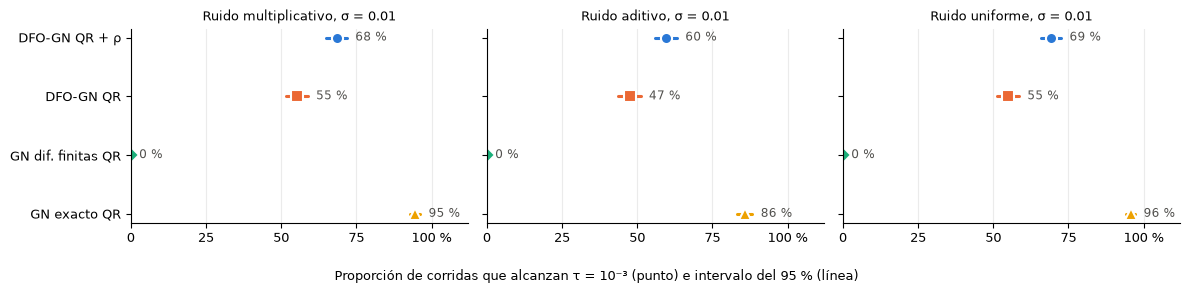

In [10]:
figura_exito(res)

**Lectura:** las diferencias finitas no alcanzan la tolerancia en ninguna corrida, porque el ruido en $J$ es del orden de $\sigma/h\approx10^{6}$. DFO-GN sí progresa, y con $\rho_k$ su proporción de éxito sube en los tres tipos de ruido. GN exacto es solo una referencia, porque en un problema sin derivadas no está disponible. Cuando $\hat p=0$, el intervalo calculado así tiene ancho cero; no significa certeza, sino que esta aproximación normal no sirve en los extremos.

## 4. ¿La mejora de $\rho_k$ es real? Diferencia pareada

In [11]:
dif = pd.concat([diferencia_pareada(df, tau=t).assign(tau=t) for t in ["exito_1e-1", "exito_1e-3", "exito_1e-5"]])
guardar("e3_diferencia_rho.csv", list(dif.columns), dif.values.tolist())
dif.round(3)

,ruido,n_pares,diferencia,error_estandar,ic95_inf,ic95_sup,tau
0,multiplicativo,700,0.084,0.013,0.060,0.109,exito_1e-1
1,aditivo,700,0.021,0.008,0.006,0.037,exito_1e-1
2,uniforme,700,0.091,0.011,0.069,0.114,exito_1e-1
0,multiplicativo,700,0.133,0.016,0.101,0.165,exito_1e-3
1,aditivo,700,0.121,0.014,0.094,0.149,exito_1e-3
2,uniforme,700,0.143,0.015,0.113,0.173,exito_1e-3
0,multiplicativo,700,0.151,0.017,0.119,0.184,exito_1e-5
1,aditivo,700,0.094,0.012,0.071,0.117,exito_1e-5
2,uniforme,700,0.177,0.016,0.146,0.208,exito_1e-5


**Lectura:** si el intervalo no contiene el 0, la mejora no se explica por el azar de las semillas.

## 5. Las tres tolerancias

In [12]:
tabla = pd.concat([resumen_exito(df, t).assign(tau=t) for t in ["exito_1e-1", "exito_1e-3", "exito_1e-5"]])
guardar("e3_exito_por_tau.csv", list(tabla.columns), tabla.values.tolist())
tabla.pivot_table(index=["ruido", "metodo"], columns="tau", values="p_exito", sort=False).round(3)

tau                                exito_1e-1  exito_1e-3  exito_1e-5
ruido          metodo                                                
multiplicativo DFO-GN QR + ρ            0.777       0.684       0.531
               DFO-GN QR                0.693       0.551       0.380
               GN dif. finitas QR       0.000       0.000       0.000
               GN exacto QR             0.999       0.946       0.804
aditivo        DFO-GN QR + ρ            0.790       0.596       0.300
               DFO-GN QR                0.769       0.474       0.206
               GN dif. finitas QR       0.000       0.000       0.000
               GN exacto QR             0.896       0.857       0.601
uniforme       DFO-GN QR + ρ            0.784       0.691       0.550
               DFO-GN QR                0.693       0.549       0.373
               GN dif. finitas QR       0.000       0.000       0.000
               GN exacto QR             1.000       0.957       0.801

## 6. Estabilización de la estimación

Al crecer el número de corridas, $\hat p$ se estabiliza (Ley de los Grandes Números) y el error estándar cae como $1/\sqrt n$: para reducirlo a la mitad hacen falta cuatro veces más corridas.

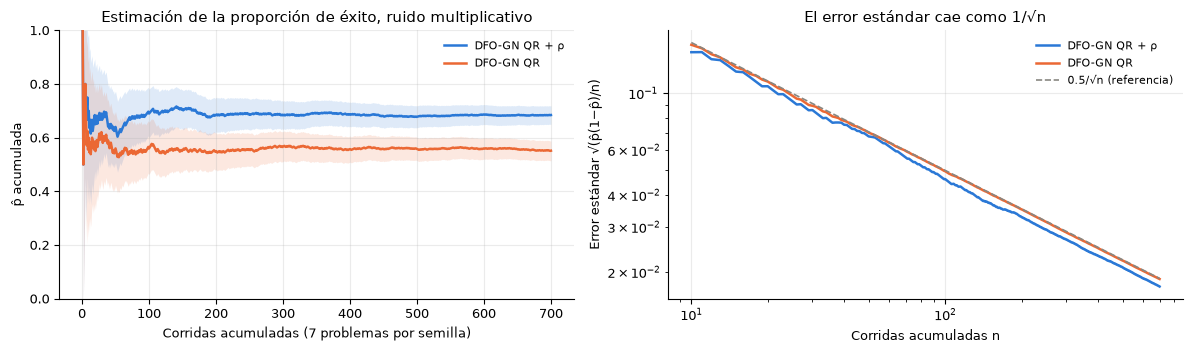

In [13]:
figura_estabilizacion(df)

## 7. Por problema

In [14]:
por_problema = df.groupby(["ruido", "problema", "metodo"], sort=False)["exito_1e-3"].mean().unstack("metodo")[METODOS_MC]
guardar("e3_exito_por_problema.csv", ["ruido", "problema", *METODOS_MC], [[*i, *v] for i, v in zip(por_problema.index, por_problema.values.tolist())])
por_problema.round(2)

metodo                              DFO-GN QR + ρ  DFO-GN QR  \
ruido          problema                                        
multiplicativo Rosenbrock                    0.29       0.30   
               Freudenstein & Roth           0.01       0.00   
               Helical Valley                0.74       0.41   
               Bard                          1.00       1.00   
               Powell Singular               1.00       0.68   
               Kowalik & Osborne             0.75       0.57   
               Watson                        1.00       0.90   
aditivo        Rosenbrock                    0.21       0.19   
               Freudenstein & Roth           0.02       0.01   
               Helical Valley                1.00       0.95   
               Bard                          1.00       1.00   
               Powell Singular               1.00       0.73   
               Kowalik & Osborne             0.00       0.00   
               Watson                        0.94       0.44   
uniforme       Rosenbrock                    0.39       0.23   
               Freudenstein & Roth           0.00       0.00   
               Helical Valley                0.74       0.49   
               Bard                          1.00       1.00   
               Powell Singular               1.00       0.70   
               Kowalik & Osborne             0.71       0.61   
               Watson                        1.00       0.81   

metodo                              GN dif. finitas QR  GN exacto QR  
ruido          problema                                               
multiplicativo Rosenbrock                          0.0          0.99  
               Freudenstein & Roth                 0.0          0.64  
               Helical Valley                      0.0          1.00  
               Bard                                0.0          1.00  
               Powell Singular                     0.0          1.00  
               Kowalik & Osborne                   0.0          0.99  
               Watson                              0.0          1.00  
aditivo        Rosenbrock                          0.0          1.00  
               Freudenstein & Roth                 0.0          1.00  
               Helical Valley                      0.0          1.00  
               Bard                                0.0          1.00  
               Powell Singular                     0.0          1.00  
               Kowalik & Osborne                   0.0          0.00  
               Watson                              0.0          1.00  
uniforme       Rosenbrock                          0.0          1.00  
               Freudenstein & Roth                 0.0          0.71  
               Helical Valley                      0.0          1.00  
               Bard                                0.0          1.00  
               Powell Singular                     0.0          1.00  
               Kowalik & Osborne                   0.0          0.99  
               Watson                              0.0          1.00

**Lectura:** el efecto de $\rho_k$ no es igual en todos los problemas; la tabla muestra dónde ayuda más.